# Step 3 — Inspect the optimised ERP across scales
## Rerproduces Figure 9 in the manuscript

Loads the fitted network and visualises the supra-threshold ERP together with the underlying
multi-scale dynamics.

### Panels
| function | content |
|---|---|
| `plot_drive_hist` | Fig. 9 b, top, proximal / distal evoked-drive spike histograms |
| `plot_erp` | Fig. 9b, bottom, model vs. experimental ERP dipole (+ RMSE) |
| `plot_raster` | Fig. 9 c, network spike raster with overlaid layer dipoles |
| `plot_firing_rates` | Fig. 9d, per-cell-type firing rate over time |
| `plot_l23_vsec` / `plot_l5_vsec` | Fig. 9e, membrane potential along the apical dendrite (section legend) |
| `plot_ca` | Fig. 9f, apical-tuft calcium (total), L2/3 + L5 |
| `plot_ca_nmda` | Fig. 9g, apical-tuft calcium, VGCCs blocked (NMDA-only), L2/3 + L5 |
| `plot_gabaa` | Fig. 9h, somatic GABA_A current, L2/3 + L5 |

In [1]:
# Author: Katharina Duecker
# Last checked: 18-Oct-2026

In [2]:
# # ONLY RUN ON OSCAR IF USING MPI (BROWN U HPC)

# import os

# # Use conda's newer libstdc++ instead of the system one
# conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
# ld_path = os.environ.get("LD_LIBRARY_PATH", "")
# os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# # UCX settings (from before)
# os.environ["UCX_TLS"] = "tcp,self,sm"
# os.environ["UCX_NET_DEVICES"] = "all"


# # MPI paths
# mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
# mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
# if mpi_bin not in os.environ["PATH"]:
#     os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
# if mpi_lib not in ld_path:
#     os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"


# # Add MPI bin directory to PATH
# mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
# if mpi_bin not in os.environ["PATH"]:
#     os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

# # print("Updated PATH to include MPI")
# # print("MPI location:", mpi_bin)

# import os
# print("PATH:", os.environ.get('PATH', 'NOT SET'))
# print("Which mpiexec:")
# import subprocess
# result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
# print(result.stdout if result.returncode == 0 else "mpiexec not found")

In [ ]:
import os
import os.path as op
from functools import partial

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import hnn_core

from hnn_core import simulate_dipole, read_dipole, average_dipoles, JoblibBackend, MPIBackend
from hnn_core.dipole import _rmse, _rmse_corr
from step2_optimize_ERP_cma import set_params_opt_drives
import numpy as np
from hnn_core import write_network_configuration, read_network_configuration
import pickle
from hnn_tuning.plot_utils import add_scalebar
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from step2_optimize_ERP_cma import rmse_corr_spike_times
from hnn_tuning import REPO_ROOT, NETWORK_SIM, results_dir
pth = str(REPO_ROOT)

import sys
#from opt_ERP_cma import get_constraints_init_params, set_up_drives_empty
col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255

out_pth = results_dir('network_sim', 'ERP')
n_procs = 20

# colormaps
l5_cols_tone = ['k','#2A3760','#36477B','#425796', '#5C72B7']
l23_cols_tone = ['#110308', '#420d20', '#741638', '#a52050']

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = '42'

filename = op.join(str(NETWORK_SIM / 'ERP'), 'duecker_ET_supra_ERP.json')

In [4]:
# Source-localized SI Dipole
pathgen = op.join(f'{pth}/data/hnn-data/')

data_url = f'{pth}/data/hnn-data/MEG_detection_data/S1_SupraT.txt'
exp_dpl = read_dipole(data_url)

tstop = exp_dpl.times[-1]
scaling_factor = 1000
smooth_win = 5

In [ ]:
# Load optimizer object
with open(op.join(out_pth, 'opt_ERP_cma_100_sigma0_0.05.pkl'), 'rb') as file:
        optim = pickle.load(file)

# store network configuration
optim.net_._model_variant = "duecker_ET_model"                  # wasn't an attribute when network was tuned.
write_network_configuration(optim.net_, filename)

net = read_network_configuration(filename)
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(-500,2200,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)

/Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/network.py:914: FutureWarning: `Network.set_cell_positions` will be deprecated in favor of `Network.update_cell_positions` in future releases.
  warnings.warn(


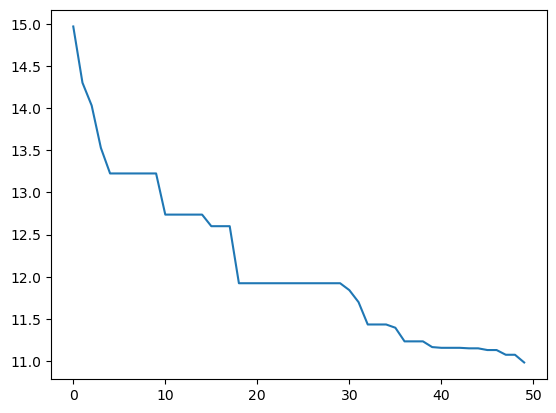

In [6]:
# loss over epochs (not shown in manuscript)
fig, ax = plt.subplots()
ax.plot(optim.obj_)

In [7]:
# Simulate dipole with optimized network
with JoblibBackend(n_jobs=3):
    dpl_opt = simulate_dipole(net, tstop=tstop, n_trials=3, dt=0.025, record_ca='all', record_vsec='all', record_isec='all')

dpl_opt = [d.scale(scaling_factor).smooth(smooth_win) for d in dpl_opt]
avg_dpl = average_dipoles(dpl_opt)

Joblib will run 3 trial(s) in parallel by distributing trials over 3 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
[Done]
[Done]
Trial 3: 0.03 ms...
Trial 2: 0.03 ms...
Trial 1: 0.03 ms...
Trial 3: 10.0 ms...
Trial 2: 10.0 ms...
Trial 1: 10.0 ms...
Trial 3: 20.0 ms...
Trial 2: 20.0 ms...
Trial 1: 20.0 ms...
Trial 3: 30.0 ms...
Trial 2: 30.0 ms...
Trial 1: 30.0 ms...
Trial 3: 40.0 ms...
Trial 1: 40.0 ms...
Trial 2: 40.0 ms...
Trial 3: 50.0 ms...
Trial 1: 50.0 ms...
Trial 2: 50.0 ms...
Trial 3: 60.0 ms...
Trial 2: 60.0 ms...
Trial 1: 60.0 ms...
Trial 3

In [8]:
# Block VGGCs to find calcium increase through NMDA

def net_block_ca(net_no_ca):

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1])
        net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1])

    sections = ['apical_trunk', 'apical_1', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1])
        net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1])


    return net_no_ca

In [9]:
# run the network with dendritic Ca channels (VGCCs) blocked, so tuft calcium reflects NMDA influx only (used by plot_ca_nmda)
net_no_ca = read_network_configuration(filename)
net_no_ca = net_block_ca(net_no_ca)
with MPIBackend(mpi_cmd='mpiexec'):
    dpl_test = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1, dt=0.025,
                            record_ca='all', record_vsec='all', record_isec='all')

MPI will run 1 trial(s) sequentially by distributing network neurons over 11 processes.
numprocs=11
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core

## Panels

Each panel below plots the network activity associated with the ERP at a different scale via a `plot_<panel>(ax)` function.
`plot_all()` at the end assembles them into the composite manuscript figure.

### Evoked drives

<Axes: label='Spike histogram', ylabel='Counts'>

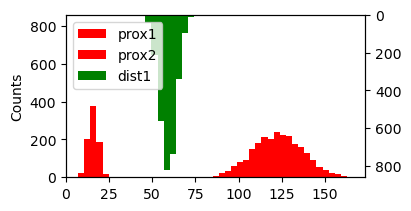

In [10]:
def plot_drive_hist(ax):
    """Evoked-drive spike histograms via CellResponse.plot_spikes_hist."""
    net.cell_response.plot_spikes_hist(ax=ax, show=False, invert_spike_types='dist1', color=['g', 'r', 'r'])
    return ax


fig, ax = plt.subplots(figsize=(4, 2), constrained_layout=True)
plot_drive_hist(ax)

### ERP and spiking

<Axes: xlabel='time (ms)', ylabel='dipole (nA m)'>

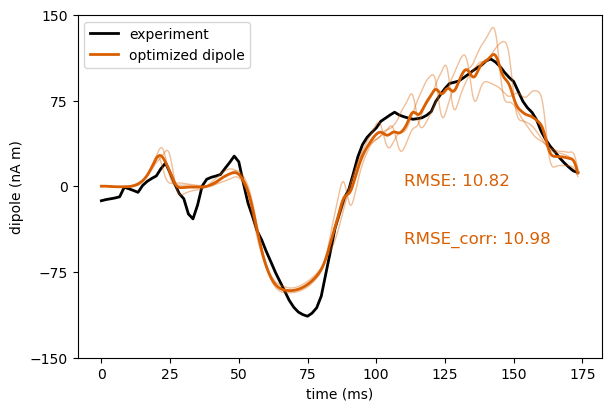

In [11]:
def plot_erp(ax):
    """Model ERP (single trials + average, orange) vs. the experimental dipole (black), with RMSE."""
    ax.plot(exp_dpl.times, exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
    for dpl in dpl_opt:
        ax.plot(dpl.times, dpl.data['agg'], color=col_lines[1], linewidth=1, alpha=0.4)
    ax.plot(avg_dpl.times, avg_dpl.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
    ax.set_ylim([-150, 150])
    ax.set_yticks([-150, -75, 0, 75, 150])
    ax.text(110, 0.5, 'RMSE: %.2f' % _rmse(avg_dpl, exp_dpl, tstart=0, tstop=1000), fontsize=12, color=col_lines[1])
    ax.text(110, -50, 'RMSE_corr: %.2f' % _rmse_corr(avg_dpl, exp_dpl, tstart=0, tstop=1000), fontsize=12, color=col_lines[1])
    ax.legend()
    ax.set_xlabel('time (ms)')
    ax.set_ylabel('dipole (nA m)')
    return ax


fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
plot_erp(ax)

<Axes: xlabel='time (ms)', ylabel='neuron index'>

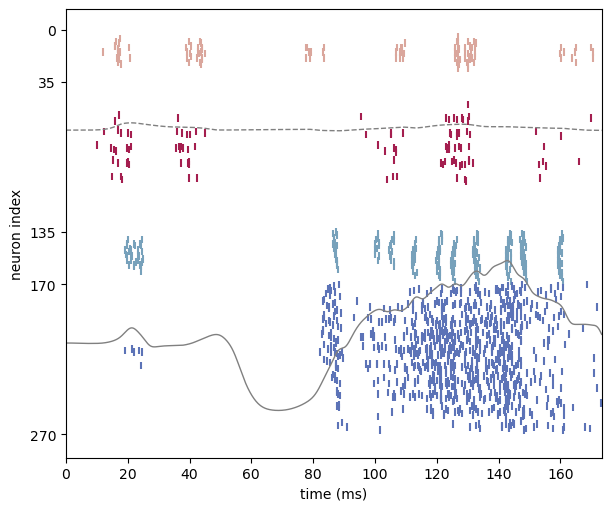

In [12]:
def plot_raster(ax):
    """Network spike raster with the layer dipoles overlaid."""
    net.cell_response.plot_spikes_raster(
        ax=ax, show_legend=False, show=False, yticks=[0, 35, 135, 170, 270],
        overlay_dipoles=True, dpl=dpl_opt, title='', ylabel='neuron index', xlabel='time (ms)')
    return ax


fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
plot_raster(ax)

array([<Axes: >, <Axes: >, <Axes: >,
       <Axes: xlabel='time (ms)', ylabel='firing rate (Hz)'>],
      dtype=object)

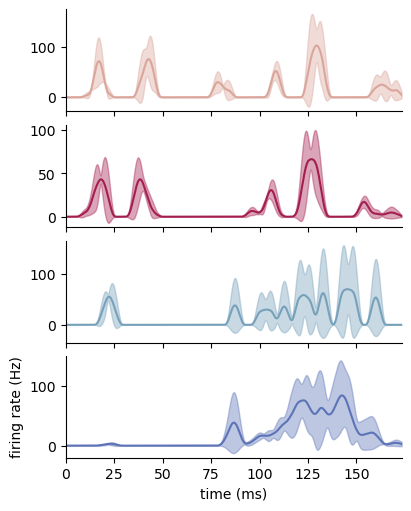

In [13]:
def plot_firing_rates(axes, window_length_ms=10):
    """Per-cell-type firing rate over time (one axis per cell type)."""
    net.cell_response.plot_firing_rate_time(
        ax=list(axes), window_length=window_length_ms, show_legend=False, show=False)
    return axes


fig, axes = plt.subplots(4, 1, figsize=(4, 5), sharex=True, constrained_layout=True)
plot_firing_rates(axes)

### Membrane potential (along apical dendrite)

<Axes: >

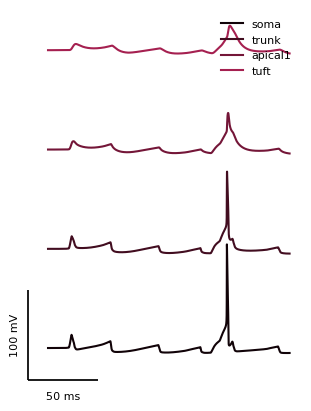

In [14]:
def plot_l23_vsec(ax):
    """L2/3 pyramidal membrane potential along the apical dendrite (one offset trace per section)."""
    sections = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
    labels = ['soma', 'trunk', 'apical1', 'tuft']
    # representitive cell: median firing rate 
    gids = np.array(net.cell_response.spike_gids[0])
    l23_gids = gids[(gids < 135) & (gids > 34)]
    l23_spikes, counts = np.unique(l23_gids, return_counts=True)
    sort_counts = np.argsort(counts)
    idx_median = int(len(sort_counts)/2)
    gid_oi=l23_spikes[sort_counts[idx_median]]
    for i, section in enumerate(sections):
        v = np.array(net.cell_response.vsec[0][gid_oi][section])
        ax.plot(net.cell_response.times, v + i * 110, color=l23_cols_tone[i], linewidth=1.5, label=labels[i])
    ax.legend(loc='upper right', frameon=False, fontsize=8)
    add_scalebar(ax, x_len=50, y_len=100, x_label='50 ms', y_label='100 mV')
    return ax


fig, ax = plt.subplots(figsize=(3, 4), constrained_layout=True)
plot_l23_vsec(ax)

<Axes: >

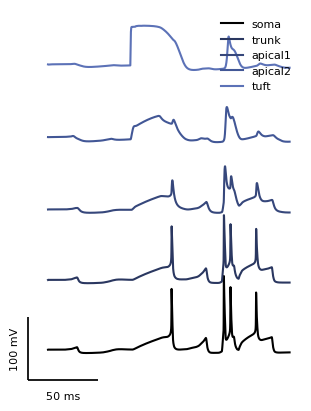

In [15]:
def plot_l5_vsec(ax):
    """L5 pyramidal membrane potential along the apical dendrite (one offset trace per section)."""
    sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    labels = ['soma', 'trunk', 'apical1', 'apical2', 'tuft']
    # representitive cell: median firing rate 
    gids = np.array(net.cell_response.spike_gids[0])
    l5_gids = gids[(gids < 270) & (gids > 169)]
    l5_spikes, counts = np.unique(l5_gids, return_counts=True)
    sort_counts = np.argsort(counts)
    idx_median = int(len(sort_counts)/2)
    gid_oi=l5_spikes[sort_counts[idx_median]]
    for i, section in enumerate(sections):
        v = np.array(net.cell_response.vsec[0][gid_oi][section])
        ax.plot(net.cell_response.times, v + i * 110, color=l5_cols_tone[i], linewidth=1.5, label=labels[i])
    ax.legend(loc='upper right', frameon=False, fontsize=8)
    add_scalebar(ax, x_len=50, y_len=100, x_label='50 ms', y_label='100 mV')
    return ax


fig, ax = plt.subplots(figsize=(3, 4), constrained_layout=True)
plot_l5_vsec(ax)

### Calcium and somatic inhibition

In [16]:
# shared helpers for the calcium / inhibition heatmaps


def sorted_gids(network, cell_type):
    _REF_POS = np.array(network.pos_dict["origin"])  # reference apical position for distance-sorting cells

    """gids of `cell_type`, sorted by distance from the reference apical position."""
    order = np.argsort(np.sum(np.abs(np.array(network.pos_dict[cell_type]) - _REF_POS), axis=1))
    return [network.gid_ranges[cell_type][i] for i in order]


def tuft_ca(network, cell_type):
    """Apical-tuft [Ca] in micromolar for every `cell_type` cell, distance-sorted -> (n_cells, n_times)."""
    ca = np.array([network.cell_response.ca[0][gid]['apical_tuft'] for gid in sorted_gids(network, cell_type)])
    return ca * 1e3  # mM -> uM


def soma_gabaa(network, cell_type):
    """Somatic GABA_A current for every `cell_type` cell, distance-sorted -> (n_cells, n_times)."""
    return np.array([network.cell_response.isec[0][gid]['soma']['soma_gabaa']
                     for gid in sorted_gids(network, cell_type)])

array([<Axes: ylabel='L2/3 pyr index'>,
       <Axes: xlabel='time (ms)', ylabel='L5 pyr index'>], dtype=object)

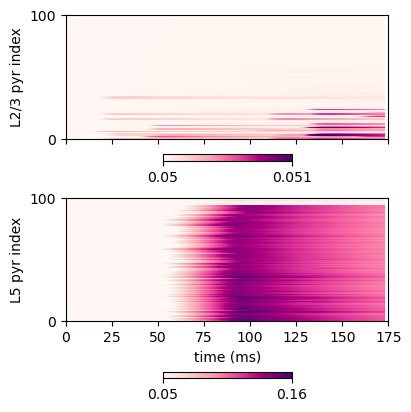

In [17]:
def plot_ca(axes, network=None):
    """Total apical-tuft calcium heatmaps: L2/3 (top) and L5 (bottom)."""
    network = net if network is None else network
    for ax, cell_type in zip(axes, ['L2_pyramidal', 'L5_pyramidal']):
        data = tuft_ca(network, cell_type)
        im = ax.pcolormesh(network.cell_response.times, np.arange(len(data)), data,
                           shading='auto', cmap='RdPu', rasterized=True)
        cb = plt.colorbar(im, ax=ax, orientation='horizontal', shrink=0.4)
        cb.set_ticks([5e-2, data.max()])
        cb.set_ticklabels([f'{5e-2:.1}', f'{data.max():.2}'])
        ax.set_ylim([0, 100]); ax.set_yticks([0, 100]); ax.set_xlim([0, 175])
    axes[0].tick_params(labelbottom=False)
    axes[1].set_xlabel('time (ms)')
    axes[0].set_ylabel('L2/3 pyr index')
    axes[1].set_ylabel('L5 pyr index')
    return axes


fig, axes = plt.subplots(2, 1, figsize=(4, 4), constrained_layout=True)
plot_ca(axes)

array([<Axes: >, <Axes: xlabel='time (ms)'>], dtype=object)

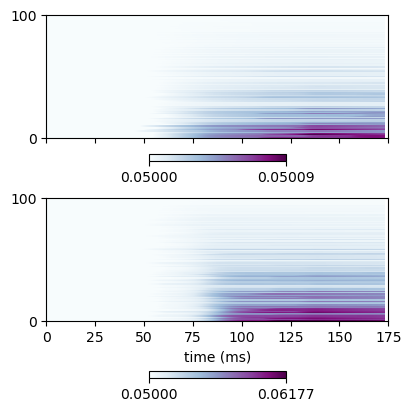

In [18]:
def plot_ca_nmda(axes):
    """Apical-tuft calcium with VGCCs blocked (NMDA-only): L2/3 (top) and L5 (bottom)."""
    for ax, cell_type in zip(axes, ['L2_pyramidal', 'L5_pyramidal']):
        data = tuft_ca(net_no_ca, cell_type)
        im = ax.pcolormesh(net_no_ca.cell_response.times, np.arange(len(data)), data,vmax=np.round(data.max(), 5),vmin=data.min(),
                           shading='auto', cmap='BuPu', rasterized=True)
        cb = plt.colorbar(im, ax=ax, orientation='horizontal', shrink=0.4)
        cb.set_ticks([data.min(), np.round(data.max(), 5)])
        ax.set_ylim([0, 100]); ax.set_yticks([0, 100]); ax.set_xlim([0, 175])
    axes[0].tick_params(labelbottom=False)
    axes[1].set_xlabel('time (ms)')

    return axes


fig, axes = plt.subplots(2, 1, figsize=(4, 4), constrained_layout=True)
plot_ca_nmda(axes)

array([<Axes: >, <Axes: xlabel='time (ms)'>], dtype=object)

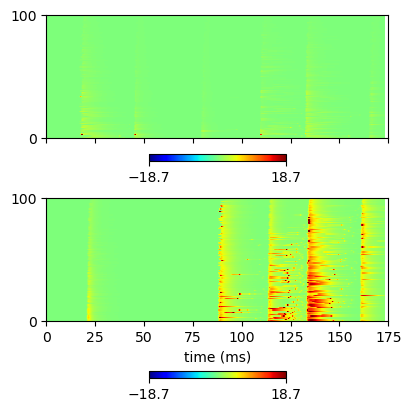

In [19]:
def plot_gabaa(axes, network=None):
    """Somatic GABA_A current heatmaps: L2/3 (top) and L5 (bottom), on a shared symmetric scale."""
    network = net if network is None else network
    data_l23 = soma_gabaa(network, 'L2_pyramidal')
    data_l5 = soma_gabaa(network, 'L5_pyramidal')
    vmax = data_l23.max()  # shared L2/3-based scale (matches the original figure)
    for ax, data in zip(axes, [data_l23, data_l5]):
        im = ax.pcolormesh(network.cell_response.times, np.arange(len(data)), data,
                           shading='auto', cmap='jet', rasterized=True, vmin=-vmax, vmax=vmax)
        cb = plt.colorbar(im, ax=ax, orientation='horizontal', shrink=0.4)
        cb.set_ticks([-np.round(vmax, 2), np.round(vmax, 2)])
        ax.set_ylim([0, 100]); ax.set_yticks([0, 100]); ax.set_xlim([0, 175])
    axes[0].tick_params(labelbottom=False)
    axes[1].set_xlabel('time (ms)')

    return axes


fig, axes = plt.subplots(2, 1, figsize=(4, 4), constrained_layout=True)
plot_gabaa(axes)

### Composite figure

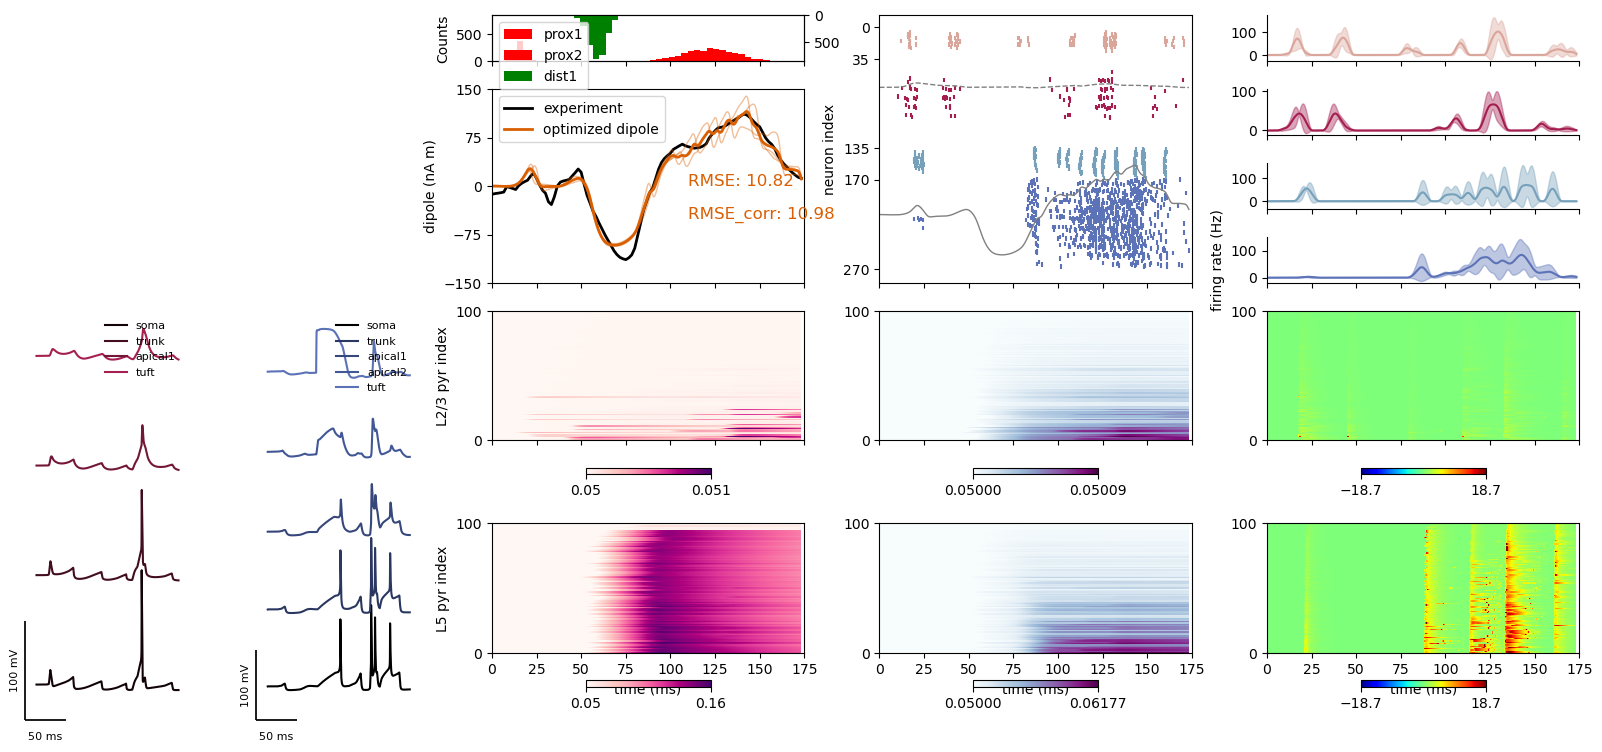

In [ ]:
def plot_all():
    """Reassemble every panel into the composite manuscript figure (section colorbars -> legends)."""
    fig = plt.figure(figsize=(20, 9))
    gs = GridSpec(6, 5, figure=fig, height_ratios=[0.25, 0.25, 0.25, 0.25, 1, 1],
                  width_ratios=[0.5, 0.5, 1, 1, 1], hspace=0.3, wspace=0.3)
    # every time-series panel shares this x-axis; the membrane-potential panels
    # (scalebar, no ticks) are deliberately left out
    ax_drives = fig.add_subplot(gs[0, 2])
    ax_erp = fig.add_subplot(gs[1:4, 2], sharex=ax_drives)
    ax_raster = fig.add_subplot(gs[:4, 3], sharex=ax_drives)
    ax_fr = [fig.add_subplot(gs[i, 4], sharex=ax_drives) for i in range(4)]
    ax_l23v = fig.add_subplot(gs[4:6, 0])
    ax_l5v = fig.add_subplot(gs[4:6, 1])
    ax_ca = [fig.add_subplot(gs[4, 2], sharex=ax_drives), fig.add_subplot(gs[5, 2], sharex=ax_drives)]
    ax_ca_nmda = [fig.add_subplot(gs[4, 3], sharex=ax_drives), fig.add_subplot(gs[5, 3], sharex=ax_drives)]
    ax_gabaa = [fig.add_subplot(gs[4, 4], sharex=ax_drives), fig.add_subplot(gs[5, 4], sharex=ax_drives)]

    plot_drive_hist(ax_drives)
    plot_erp(ax_erp)
    plot_raster(ax_raster)
    plot_firing_rates(ax_fr)
    plot_l23_vsec(ax_l23v)
    plot_l5_vsec(ax_l5v)
    plot_ca(ax_ca)
    plot_ca_nmda(ax_ca_nmda)
    plot_gabaa(ax_gabaa)

    # shared x-axis: reset the (shared) tick formatter, then show the time axis --
    # ticks + 'time (ms)' label -- only on each column's bottom panel
    import matplotlib.ticker as mticker
    ax_drives.xaxis.set_major_locator(mticker.AutoLocator())
    ax_drives.xaxis.set_major_formatter(mticker.ScalarFormatter())
    bottom = [ax_ca[1], ax_ca_nmda[1], ax_gabaa[1]]
    for a in [ax_drives, ax_erp, ax_raster, *ax_fr, *ax_ca, *ax_ca_nmda, *ax_gabaa]:
        is_bottom = a in bottom
        a.tick_params(labelbottom=is_bottom)
        a.set_xlabel('time (ms)' if is_bottom else '')

    return fig


fig = plot_all()

fig.savefig(os.path.join(out_pth, 'duecker_ET_optim_ERP.png'), dpi=300)
fig.savefig(os.path.join(out_pth, 'duecker_ET_optim_ERP.pdf'), dpi=300)